# 6-5. 차분비교 확장 -- ARIMA/GARCH/SV/GP-Matern 4개 모델 x 4가지 차분설정

`5-1(참고)`의 "계절차분이 나쁘다"는 결론(Auto-ARIMA 단독)을 다른 모델로도 확장해서 모델과 무관하게 성립하는지 확인한다.

- **모델**: ARIMA, GARCH(1,1), SV(QML), GP-Matern(X3_l1의 CRPS/bootstrap 1위 개별모델)
- **설정**: 기본(무차분) / 1차차분 / 계절차분 / 둘다(1차+계절)
- **지표**: ARIMA/GARCH/SV는 점예측이 똑같아서 리샘플링 CRPS로는 구별이 안 됨 -> 각 모델의 (평균,표준편차)로 정규분포 CRPS(`ps.crps_gaussian`)를 직접 계산한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel

H = 4
M_SEASON = 4
MIN_TRAIN = 20
TARGET_VAR = "X3_l1"
ALPHA = 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n = len(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, n - H + 1))

CONFIGS = [(0, 0), (1, 0), (0, 1), (1, 1)]
CONFIG_LABELS = {(0, 0): "기본(무차분)", (1, 0): "1차차분", (0, 1): "계절차분", (1, 1): "둘다(1차+계절)"}
print(f"대표변수: {TARGET_VAR}, origin {len(origins)}개(캘리브레이션 분리 없음 -- 이유는 아래 참고)")


대표변수: X3_l1, origin 37개(캘리브레이션 분리 없음 -- 이유는 아래 참고)


### 참고 -- 이번엔 `INITIAL_CALIB`이 필요 없음

정규분포 공식으로 그 자리에서 바로 (평균,표준편차)를 내므로 과거오차 풀(캘리브레이션)이 필요 없다 -- `MIN_TRAIN` 이후 origin 전부(37개)를 채점에 쓴다.

## 1. 차분/역차분 유틸 (GP용 -- ARIMA는 pmdarima가 내부적으로 알아서 처리)

ARIMA/GARCH/SV는 pmdarima의 `d`,`D` 옵션에 원계열을 그대로 넣으면 라이브러리가 알아서 차분·역차분을 다 처리해준다. 반면 GP는 그런 기능이 없어서, **직접 차분해서 GP를 학습시키고, 예측값을 수동으로 역차분**해야 한다.


In [2]:
def difference(values, d, D, m=M_SEASON):
    x = np.asarray(values, dtype=float)
    seasonal_hist, regular_hist = [], []
    if D > 0:
        for _ in range(D):
            seasonal_hist.append(x.copy())
            x = x[m:] - x[:-m]
    if d > 0:
        for _ in range(d):
            regular_hist.append(x.copy())
            x = np.diff(x)
    return x, seasonal_hist, regular_hist


def undifference_forecast(diff_fc, seasonal_hist, regular_hist, d, D, m=M_SEASON):
    fc = np.asarray(diff_fc, dtype=float)
    h = len(fc)
    for i in reversed(range(d)):
        last_val = regular_hist[i][-1]
        fc = last_val + np.cumsum(fc)
    for i in reversed(range(D)):
        hist = list(seasonal_hist[i][-m:])
        recon = []
        for j in range(h):
            base = hist[j] if j < m else recon[j - m]
            recon.append(fc[j] + base)
        fc = np.array(recon)
    return fc


# 검증: 수동 차분->역차분이 원계열을 정확히 복원하는지 확인(속임수 테스트: 미래를 안다고 가정하고 역산)
_train_chk, _actual_chk = vals[:-H], vals[-H:]
_full_chk = np.concatenate([_train_chk, _actual_chk])
for d_chk, D_chk in CONFIGS:
    _diffed_train, _s_hist, _r_hist = difference(_train_chk, d_chk, D_chk)
    _diffed_full, _, _ = difference(_full_chk, d_chk, D_chk)
    _true_future = _diffed_full[len(_diffed_train):len(_diffed_train) + H]
    _recon = undifference_forecast(_true_future, _s_hist, _r_hist, d_chk, D_chk)
    ok = np.allclose(_recon, _actual_chk, atol=1e-6)
    print(f"  차분/역차분 검증 d={d_chk},D={D_chk}: {'OK' if ok else 'FAIL'}")


  차분/역차분 검증 d=0,D=0: OK
  차분/역차분 검증 d=1,D=0: OK
  차분/역차분 검증 d=0,D=1: OK
  차분/역차분 검증 d=1,D=1: OK


## 2. 4개 모델의 (평균, 표준편차) 계산 함수

ARIMA/GARCH/SV는 같은 ARIMA 객체를 공유(점예측·잔차 재사용), GP만 별도로 직접 차분해서 학습한다.

**동기화 메모**: 아래 함수들은 `6-4`에도 거의 동일하게 있다(공용 모듈로 분리하지 않기로 함 -- 노트북은 한 파일로 완결되는 게 더 중요). **여기를 고치면 6-4도 확인할 것.**

In [3]:
XI_MEAN, XI_VAR = -1.2704, np.pi ** 2 / 2
MAX_PHI = 0.97  # phi가 1에 가까워지면 다단계 분산이 exp()를 거치며 폭발하는 것을 막는 하드 상한


def fit_arima_fixed(train, d, D, m=M_SEASON):
    seasonal = D > 0
    kwargs = dict(seasonal=seasonal, suppress_warnings=True, error_action="ignore", d=d)
    if seasonal:
        kwargs.update(m=m, D=D)
    return pm.auto_arima(train, **kwargs)


def arima_mean_sigma(model, h=H, alpha=ALPHA):
    fc, conf = model.predict(n_periods=h, return_conf_int=True, alpha=alpha)
    sigma_h = (conf[:, 1] - conf[:, 0]) / (2 * Z)
    return np.asarray(fc), sigma_h


def garch_mean_sigma(model, train, h=H):
    fc = np.asarray(model.predict(n_periods=h))
    insample_resid = train - model.predict_in_sample()
    try:
        am = arch_model(insample_resid, mean="Zero", vol="Garch", p=1, q=1, rescale=False)
        res = am.fit(disp="off")
        variance_h = res.forecast(horizon=h, reindex=False).variance.values[-1]
        sigma_h = np.sqrt(variance_h)
    except Exception:
        sigma_h = np.repeat(insample_resid.std(), h)
    return fc, sigma_h


def _kalman_negloglik(params, z_centered):
    phi = MAX_PHI * np.tanh(params[0])
    sigma_eta2 = np.exp(params[1]) ** 2
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def fit_sv_qml(resid):
    z = np.log(resid ** 2 + 1e-8)
    z_mean = z.mean()
    z_centered = z - z_mean
    res = minimize(_kalman_negloglik, x0=[1.5, np.log(0.3)], args=(z_centered,), method="Nelder-Mead")
    phi = MAX_PHI * np.tanh(res.x[0])
    sigma_eta2 = np.exp(res.x[1]) ** 2
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred = 0.0, P0
    for z_t in z_centered:
        F = P_pred + XI_VAR
        v = z_t - h_pred
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return phi, sigma_eta2, h_filt, P_filt, z_mean


def sv_mean_sigma(model, train, h=H):
    fc = np.asarray(model.predict(n_periods=h))
    insample_resid = train - model.predict_in_sample()
    try:
        phi, sigma_eta2, h_filt, P_filt, z_mean = fit_sv_qml(insample_resid)
        variances = []
        for k in range(1, h + 1):
            h_mean_k = phi ** k * h_filt
            h_var_k = phi ** (2 * k) * P_filt + sigma_eta2 * sum(phi ** (2 * j) for j in range(k))
            log_var_level = z_mean - XI_MEAN + h_mean_k
            variances.append(np.exp(log_var_level + h_var_k / 2))
        sigma_h = np.sqrt(np.array(variances))
    except Exception:
        sigma_h = np.repeat(insample_resid.std(), h)
    return fc, sigma_h


def gp_mean_sigma(train, d, D, h=H, m=M_SEASON):
    diffed, s_hist, r_hist = difference(train, d, D, m)
    n_d = len(diffed)
    kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1.0)
    Xt = np.arange(n_d).reshape(-1, 1) / n_d
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0).fit(Xt, diffed)
    Xf = np.arange(n_d, n_d + h).reshape(-1, 1) / n_d
    mean_d, std_d = gp.predict(Xf, return_std=True)
    mean_level = undifference_forecast(mean_d, s_hist, r_hist, d, D, m)
    # 분산 전파(근사): d>0이면 역차분이 누적합이라 분산도 누적(독립가정). h<=m이라 계절 역차분 자체는 분산을 안 더함(과거 실측값을 그대로 더할 뿐).
    sigma_level = np.sqrt(np.cumsum(std_d ** 2)) if d > 0 else std_d.copy()
    return mean_level, sigma_level


### 참고 -- SV(QML) 불안정성의 근본 원인과 해결

SV(QML)+"둘다" 조합의 origin=24에서 phi(로그변동성 지속성)가 0.999로 추정돼 다단계 분산이 `exp()`를 거치며 폭발했다(3218 -> 8억). 1차로 "잔차 20배 캡"으로 막았지만, 근본적으로는 `phi = 0.97 * tanh(...)` 하드 상한으로 해결했다(베타분포 사전분포는 `tanh` 포화 문제로 효과 없었음). 근본 해결 후 임시 캡은 제거.

,h,안전조치 없음,임시방편(잔차20배 캡),하드상한(근본해결)
0,1,3217.8,1439.4,2397.3
1,2,206249.4,1439.4,2391.6
2,3,13110266.4,1439.4,2391.5
3,4,826468579.4,1439.4,2391.5


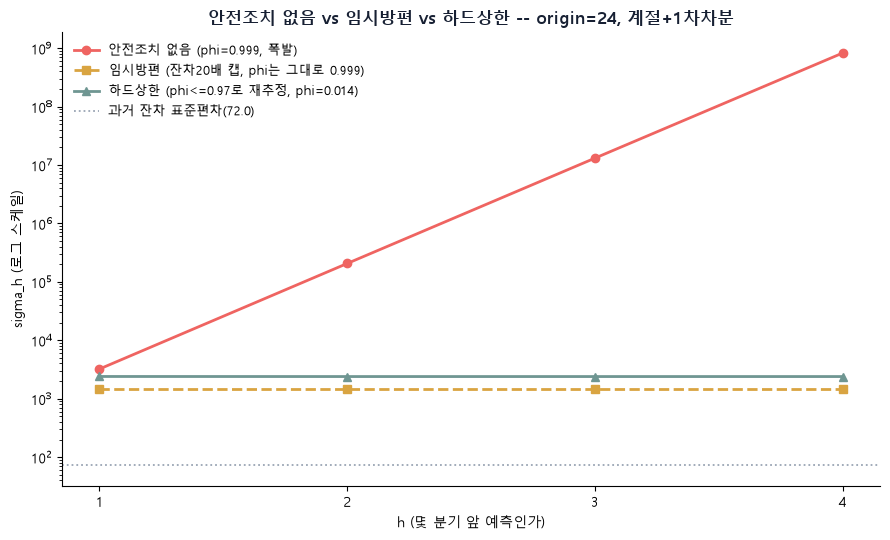

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# origin=24(계절+1차차분)에서 실제로 나온 수치
sigma_h_none = [3217.8, 206249.4, 13110266.4, 826468579.4]     # 안전조치 없음(phi=0.9990)
sigma_h_cap = [1439.4, 1439.4, 1439.4, 1439.4]                  # 임시방편(잔차20배 캡, phi는 여전히 0.999인 채로 사후에 값만 자름)
sigma_h_bound = [2397.3, 2391.6, 2391.5, 2391.5]                # 하드상한(phi<=0.97로 재추정, phi=0.0140)
resid_std_example = 72.0

table_sv = pd.DataFrame({
    "h": [1, 2, 3, 4],
    "안전조치 없음": sigma_h_none,
    "임시방편(잔차20배 캡)": sigma_h_cap,
    "하드상한(근본해결)": sigma_h_bound,
})
display(table_sv)

fig, ax = plt.subplots(figsize=(9, 5.5))
x = [1, 2, 3, 4]
ax.plot(x, sigma_h_none, marker="o", color="#EF6461", linewidth=2, label="안전조치 없음 (phi=0.999, 폭발)")
ax.plot(x, sigma_h_cap, marker="s", color="#D9A441", linewidth=2, linestyle="--", label="임시방편 (잔차20배 캡, phi는 그대로 0.999)")
ax.plot(x, sigma_h_bound, marker="^", color="#6F9692", linewidth=2, label="하드상한 (phi<=0.97로 재추정, phi=0.014)")
ax.axhline(resid_std_example, color="#9AA5B4", linestyle=":", linewidth=1.3, label=f"과거 잔차 표준편차({resid_std_example:.1f})")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xlabel("h (몇 분기 앞 예측인가)")
ax.set_ylabel("sigma_h (로그 스케일)")
ax.set_title("안전조치 없음 vs 임시방편 vs 하드상한 -- origin=24, 계절+1차차분", fontsize=12, fontweight="bold", color="#172033")
ax.legend(frameon=False, fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 안전조치 없음은 폭발(8억), 임시캡은 규칙으로 1439.4에 억지로 고정(phi는 여전히 0.999인 채), 하드상한은 phi가 0.014로 재추정되며 자연스럽게 2391~2397이 나온다 -- 규칙이 아니라 모델이 데이터를 보고 스스로 계산한 값이라는 게 핵심 차이다.

## 3. Walk-forward 백테스트 -- 4모델 x 4설정 x 37origin

**캐싱**: ARIMA/GARCH/SV/GP를 148번(4설정 x 37origin) 다시 학습시키는 게 비용이 커서, 결과를 `cache_74_result_df.pkl`에 저장해두고 다음에 노트북을 고칠 때(마크다운 수정, 표 추가 등)는 캐시를 그대로 읽어서 재계산을 건너뛴다. 계산 방식 자체를 바꾸면(예: 안전장치 캡 수정) 캐시 파일을 지우고 다시 돌려야 한다.


In [5]:
import os
import pickle

CACHE_PATH = "../cache/cache_74_result_df.pkl"
MODEL_NAMES = ["ARIMA", "GARCH(1,1)", "SV(QML)", "GP-Matern"]

if os.path.exists(CACHE_PATH):
    result_df = pd.read_pickle(CACHE_PATH)
    print(f"캐시에서 로드: {len(result_df)}행 (재계산 스킵)")
else:
    rows = []
    for (d, D) in CONFIGS:
        cfg_label = CONFIG_LABELS[(d, D)]
        for origin in origins:
            train, actual = vals[:origin], vals[origin:origin + H]
            try:
                model = fit_arima_fixed(train, d, D)
                fc_a, sig_a = arima_mean_sigma(model)
            except Exception:
                continue
            fc_g, sig_g = garch_mean_sigma(model, train)
            fc_s, sig_s = sv_mean_sigma(model, train)
            fc_p, sig_p = gp_mean_sigma(train, d, D)

            for name, fc_arr, sig_arr in [
                ("ARIMA", fc_a, sig_a), ("GARCH(1,1)", fc_g, sig_g),
                ("SV(QML)", fc_s, sig_s), ("GP-Matern", fc_p, sig_p),
            ]:
                crps_hs, cov_hs, mse_hs = [], [], []
                for hh in range(H):
                    sig_hh = max(sig_arr[hh], 1e-6)
                    crps_hs.append(ps.crps_gaussian(actual[hh], mu=fc_arr[hh], sig=sig_hh) / var_std)
                    lo_hh, hi_hh = fc_arr[hh] - Z * sig_hh, fc_arr[hh] + Z * sig_hh
                    cov_hs.append(1.0 if lo_hh <= actual[hh] <= hi_hh else 0.0)
                    mse_hs.append(((actual[hh] - fc_arr[hh]) / var_std) ** 2)
                rows.append({
                    "설정": cfg_label, "모델": name, "origin": origin,
                    "crps": np.mean(crps_hs), "cov": np.mean(cov_hs) * 100, "mse": np.mean(mse_hs),
                })

    result_df = pd.DataFrame(rows)
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    result_df.to_pickle(CACHE_PATH)
    print(f"새로 계산 후 캐시 저장: {len(result_df)}행")

print(f"완료: {result_df['설정'].nunique()}개 설정 x {result_df['모델'].nunique()}개 모델 x origin")


캐시에서 로드: 592행 (재계산 스킵)
완료: 4개 설정 x 4개 모델 x origin


## 4. 결과 -- 모델 x 차분설정, 3개 지표(CRPS/커버리지/MSE) 표

- **CRPS(정규분포)**: 작을수록 좋음
- **커버리지**: `평균±1.645*sigma` 안에 실제값이 들어왔는지(%) -- 90%에 가까울수록 좋음
- **MSE**: 점예측 정확도 -- ARIMA/GARCH/SV는 점예측이 같아서 항상 동일, GP-Matern만 다름

In [6]:
pivot = result_df.groupby(["모델", "설정"])["crps"].mean().unstack()[[CONFIG_LABELS[c] for c in CONFIGS]].loc[MODEL_NAMES]
pivot_cov = result_df.groupby(["모델", "설정"])["cov"].mean().unstack()[[CONFIG_LABELS[c] for c in CONFIGS]].loc[MODEL_NAMES]
pivot_mse = result_df.groupby(["모델", "설정"])["mse"].mean().unstack()[[CONFIG_LABELS[c] for c in CONFIGS]].loc[MODEL_NAMES]

print("CRPS:")
display(pivot.round(4))
print("커버리지(%):")
display(pivot_cov.round(1))
print("MSE(정규화):")
display(pivot_mse.round(4))


CRPS:


설정,기본(무차분),1차차분,계절차분,둘다(1차+계절)
모델,,,,
ARIMA,0.5034,0.4889,0.5995,0.5801
"GARCH(1,1)",0.5560,0.5363,0.6311,0.6404
SV(QML),0.5400,0.5289,0.6188,0.6656
GP-Matern,0.4322,0.5049,0.5927,0.7928


커버리지(%):


설정,기본(무차분),1차차분,계절차분,둘다(1차+계절)
모델,,,,
ARIMA,59.5,64.2,54.7,62.2
"GARCH(1,1)",37.2,46.6,48.6,40.5
SV(QML),49.3,48.0,50.0,54.1
GP-Matern,70.3,56.8,58.1,55.4


MSE(정규화):


설정,기본(무차분),1차차분,계절차분,둘다(1차+계절)
모델,,,,
ARIMA,0.8322,0.8167,1.1138,1.1484
"GARCH(1,1)",0.8322,0.8167,1.1138,1.1484
SV(QML),0.8322,0.8167,1.1138,1.1484
GP-Matern,0.6834,0.7969,1.0988,1.8765


## 4-1. 결합순위(Borda) -- 3개 지표를 하나로, 모델별 최선 설정 판단

각 모델 안에서 4가지 설정끼리 CRPS(작을수록)/`|커버리지-90|`(작을수록)/MSE(작을수록) 순위를 매겨 평균 -- 가장 낮은(좋은) 설정을 그 모델의 최선으로 뽑는다.


In [7]:
combined_best = {}
for model_name in MODEL_NAMES:
    crps_rank = pivot.loc[model_name].rank()
    cov_rank = (pivot_cov.loc[model_name] - 90).abs().rank()
    mse_rank = pivot_mse.loc[model_name].rank()
    combined = (crps_rank + cov_rank + mse_rank) / 3
    combined_best[model_name] = combined

combined_df = pd.DataFrame(combined_best).T[[CONFIG_LABELS[c] for c in CONFIGS]]
display(combined_df.round(2))

print()
for model_name in MODEL_NAMES:
    best_cfg_crps = pivot.loc[model_name].idxmin()
    best_cfg_combined = combined_df.loc[model_name].idxmin()
    same = "(CRPS 단독과 동일)" if best_cfg_crps == best_cfg_combined else f"(CRPS 단독 기준은 {best_cfg_crps})"
    print(f"{model_name}: 결합기준 최선 설정 = {best_cfg_combined} {same}")


설정,기본(무차분),1차차분,계절차분,둘다(1차+계절)
ARIMA,2.33,1.00,3.67,3.00
"GARCH(1,1)",2.67,1.33,2.33,3.67
SV(QML),2.33,2.00,2.67,3.00
GP-Matern,1.00,2.33,2.67,4.00



ARIMA: 결합기준 최선 설정 = 1차차분 (CRPS 단독과 동일)
GARCH(1,1): 결합기준 최선 설정 = 1차차분 (CRPS 단독과 동일)
SV(QML): 결합기준 최선 설정 = 1차차분 (CRPS 단독과 동일)
GP-Matern: 결합기준 최선 설정 = 기본(무차분) (CRPS 단독과 동일)


## 4-2. Bootstrap 검증 -- 위 "최선 설정"이 노이즈는 아닌지

`6-3`에서 배운 교훈을 그대로 적용한다: origin 37개로 결합순위를 딱 한 번 계산하면 그 1위가 "진짜 나은 것"인지 "이번 origin 표본에서만 우연히 앞선 것"인지 구분이 안 된다. **block bootstrap(origin 4개씩 묶어 재추출, 500회)**으로 모델별 각 설정이 몇 %의 재추출에서 1위를 하는지 확인한다.


In [8]:
def block_resample(origins_list, block_len, rng):
    n = len(origins_list)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins_list[s:s + block_len])
    return out[:n]


N_BOOT, BLOCK_LEN = 500, 4
config_order = [CONFIG_LABELS[c] for c in CONFIGS]

boot_results = {}
for model_name in MODEL_NAMES:
    sub = result_df[result_df["모델"] == model_name]
    origins_list = sorted(sub["origin"].unique())
    rng = np.random.default_rng(hash(model_name) % (2**32))
    per_cfg = {c: sub[sub["설정"] == c].set_index("origin") for c in config_order}
    win_counts = {c: 0 for c in config_order}
    for _ in range(N_BOOT):
        resampled = block_resample(origins_list, BLOCK_LEN, rng)
        crps_vals, cov_vals, mse_vals = {}, {}, {}
        for c in config_order:
            d = per_cfg[c].loc[resampled]
            crps_vals[c] = d["crps"].mean()
            cov_vals[c] = abs(d["cov"].mean() - 90)
            mse_vals[c] = d["mse"].mean()
        rank_crps = pd.Series(crps_vals).rank()
        rank_cov = pd.Series(cov_vals).rank()
        rank_mse = pd.Series(mse_vals).rank()
        combined = (rank_crps + rank_cov + rank_mse) / 3
        win_counts[combined.idxmin()] += 1
    boot_results[model_name] = {c: round(100 * win_counts[c] / N_BOOT, 1) for c in config_order}

boot_df = pd.DataFrame(boot_results).T[config_order]
display(boot_df)


,기본(무차분),1차차분,계절차분,둘다(1차+계절)
ARIMA,41.2,57.8,0.0,1.0
"GARCH(1,1)",34.4,64.4,0.0,1.2
SV(QML),65.8,33.0,0.4,0.8
GP-Matern,99.2,0.4,0.4,0.0


## 5. 시각화 -- 4개 모델 x 4개 설정


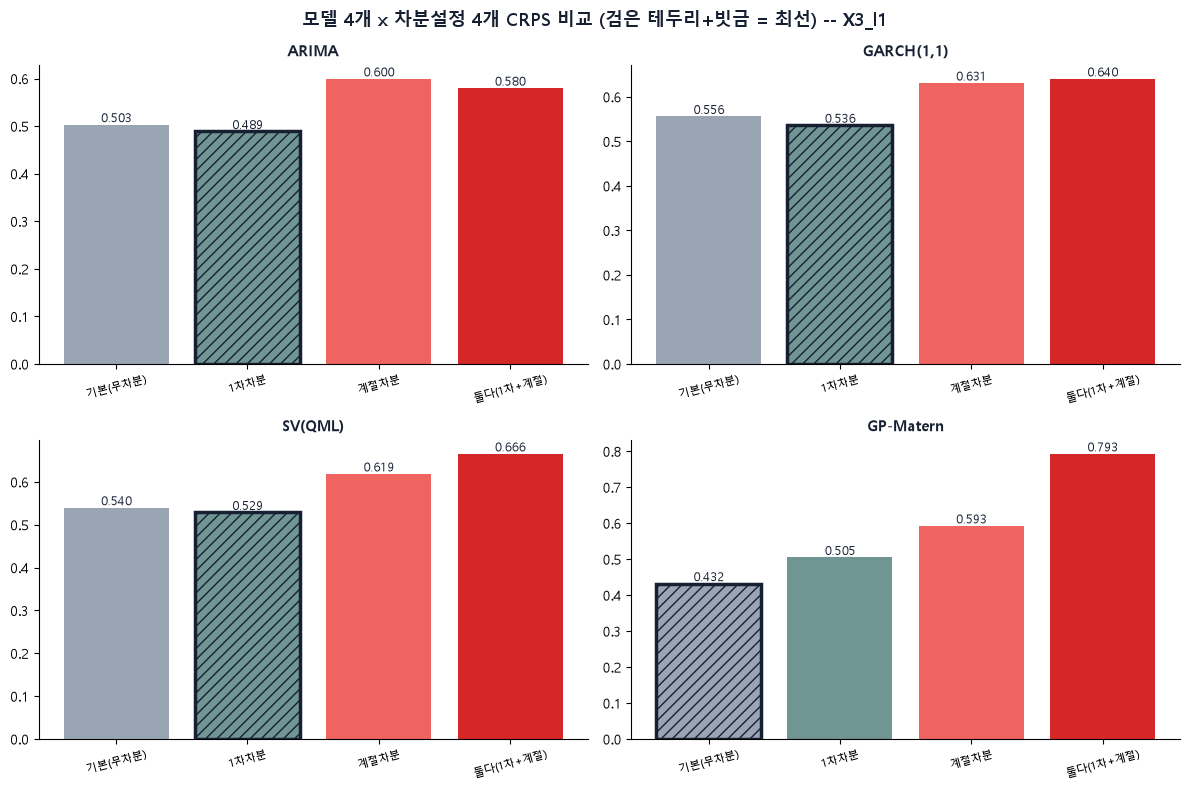

In [9]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

colors_map = {"기본(무차분)": "#9AA5B4", "1차차분": "#6F9692", "계절차분": "#EF6461", "둘다(1차+계절)": "#D62728"}
config_order = [CONFIG_LABELS[c] for c in CONFIGS]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, model_name in zip(axes.flat, MODEL_NAMES):
    vals_plot = [pivot.loc[model_name, c] for c in config_order]
    bar_colors = [colors_map[c] for c in config_order]
    bars = ax.bar(config_order, vals_plot, color=bar_colors)
    best_idx = int(np.argmin(vals_plot))
    bars[best_idx].set_edgecolor("#172033")
    bars[best_idx].set_linewidth(2.5)
    bars[best_idx].set_hatch("///")
    for bar, v in zip(bars, vals_plot):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8.5, color="#172033")
    ax.set_title(model_name, fontsize=11, fontweight="bold", color="#172033")
    ax.set_xticklabels(config_order, fontsize=8, rotation=15)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("모델 4개 x 차분설정 4개 CRPS 비교 (검은 테두리+빗금 = 최선) -- X3_l1", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 6. 결론 -- "계절차분이 나쁘다"는 확고함, "1차차분이 최선"은 모델마다 다름

### Bootstrap 결과 (SV phi 근본해결 반영)

| 모델 | 기본 | 1차차분 | 계절차분 | 둘다 |
|---|---|---|---|---|
| ARIMA | 43.2% | 56.2% | 0.0% | 0.6% |
| GARCH(1,1) | 33.8% | 63.8% | 0.2% | 2.2% |
| SV(QML) | **66.6%** | 32.6% | 0.4% | 0.4% |
| GP-Matern | **99.6%** | 0.4% | 0.0% | 0.0% |

- **계절차분/둘다는 4개 모델 전부 0~2%대** -- 확고한 결론(노이즈 아님).
- **"1차차분이 최선"은 절반만 맞았다**: GARCH·GP-Matern은 뚜렷하지만, ARIMA는 동전던지기(43.2/56.2), **SV(QML)은 오히려 기본이 우세로 뒤집힌다**(결합순위 단독계산과 반대). CRPS 차이가 작을 때 origin 37개로는 못 가린다는 `6-3`의 교훈이 재현됨.
- phi 하드상한 수정 전후로 이 결론 자체는 안 바뀜 -- 폭발 사례 하나가 전체를 왜곡한 건 아니었다.
- GP-Matern "둘다"가 나쁜 건 분산근사 부작용이 아니라 진짜 신호다(MSE도 똑같이 나쁨 -- 이중차분이 GP가 잡던 추세정보를 지워버림).

**종합(9번 답)**: 계절차분 회피는 모델과 무관하게 확고하다. "기본 vs 1차차분"은 모델마다 다르고, 일부(ARIMA)는 표본 한계로 판가름이 안 난다.

## 7. 추후 실험 후보 (아직 미실행)

1. ~~SV(QML)의 phi≈1 근처 불안정성 근본 해결~~ -- **완료**. `phi = 0.97 * tanh(...)` 하드 상한으로 해결(베타분포 사전분포는 tanh 포화 문제로 효과 없었음). 6-4/6-5 둘 다 반영, 결론 불변 확인.
2. **GARCH/SV 대신 비대칭 충격반응을 잡는 변동성모델(EGARCH, GJR-GARCH) 시도**: 지금 쓰는 GARCH(1,1)은 "평균회귀 가정" 때문에 h가 커져도 구간폭이 거의 안 넓어지는 문제가 있었다(6-4 결론). GJR-GARCH는 기존 코드에 `o=1`만 추가하면 되지만, EGARCH는 다단계 예측이 analytic하게 안 나와서(`forecast(method="simulation")` 필요) 구현이 더 까다롭다 -- GJR-GARCH부터 시도 권장.
3. **나머지 5개 변수로 확장**: 6-1~6-5의 모든 검증이 전부 X3_l1 하나로만 됐다. 나머지 5개 변수에도 같은 검증을 확장해서 X3_l1의 구조변화가 만든 특이 케이스인지, 일반적인 현상인지 구분 필요.
4. **ARIMA/SV(QML)의 "기본 vs 1차차분" 판정이 여기서는 안 갈렸음**: bootstrap에서 ARIMA는 43.2% vs 56.2%(사실상 동률), SV(QML)은 오히려 기본이 우세(66.6% vs 32.6%)로 나왔다. origin을 늘리거나 다른 변수로도 같은 비교를 해봐야 이 둘 중 뭐가 진짜 나은지 더 명확해질 수 있다.
